# Quimil — preparação da tabela para ML

Partimos das duas tabelas do notebook 01 e entregamos uma linha por bloco completo de
**30 minutos**. Preditores: **GHI e temperatura ambiente**. Alvo: **potência ativa média, em W**.

Aqui ficam somente as decisões que mudam a tabela: pareamento, corte operacional,
cobertura, irradiância e indicadores após limpeza. Todo o código está neste notebook.

In [1]:
from datetime import UTC, datetime
import hashlib
import json
from pathlib import Path

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data/raw").is_dir())
SILVER_DIR = ROOT / "data/silver"
GOLD_DIR = ROOT / "data/gold"
FIGURES_DIR = ROOT / "reports/figures/eda/gold"
GOLD_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

inverter = pd.read_parquet(SILVER_DIR / "inverter.parquet")
weather = pd.read_parquet(SILVER_DIR / "weather.parquet")
cleaning_dates = pd.to_datetime(
    [
        "2025-05-01",
        "2025-07-24",
        "2025-08-15",
        "2025-09-23",
        "2026-06-25",
        "2026-08-10",
        "2026-10-03",
    ]
)
cutoff = pd.Timestamp("2026-08-12 11:35")
min_ghi = 200.0
window_days = (7, 15, 30)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
%matplotlib inline

## 1. Parear as medições dos mesmos instantes

Não encontramos horários duplicados. As fontes coincidem em **81.859 timestamps**.
Ignorar apenas os segundos mantém exatamente esse número: os 32 horários meteorológicos
com segundos também estão fora dos minutos da grade, como `13:29:39`.

**Decisão:** pareamento exato antes das médias. Não arredondamos relógios nem convertemos
fuso. Recuperar alguns pontos por proximidade exigiria resolver colisões e confirmar a
sincronização dos equipamentos. Os registros sem par continuam nas tabelas originais.

In [2]:
# Um para um: a mesma observação de potência e ambiente em cada timestamp.
paired = (
    inverter[["timestamp", "total_active_power"]]
    .merge(weather[["timestamp", "ghi", "temp_amb"]], on="timestamp", validate="one_to_one")
    .sort_values("timestamp")
    .reset_index(drop=True)
)
source_records = []
for name, frame in {"inversor": inverter, "meteorologia": weather}.items():
    off_grid = frame["timestamp"].ne(frame["timestamp"].dt.floor("5min"))
    matched = frame["timestamp"].isin(paired["timestamp"])
    source_records.append(
        {
            "source": name,
            "input_rows": len(frame),
            "exact_pairs": int(matched.sum()),
            "unpaired_rows": int((~matched).sum()),
            "off_grid_rows": int(off_grid.sum()),
            "off_grid_unpaired_rows": int((off_grid & ~matched).sum()),
        }
    )
source_audit = pd.DataFrame(source_records)
display(
    source_audit.rename(
        columns={
            "source": "fonte",
            "input_rows": "leituras",
            "exact_pairs": "pares_exatos",
            "unpaired_rows": "sem_par",
            "off_grid_rows": "fora_da_grade",
            "off_grid_unpaired_rows": "fora_da_grade_sem_par",
        }
    )
)

,fonte,leituras,pares_exatos,sem_par,fora_da_grade,fora_da_grade_sem_par
0,inversor,82804,81859,945,0,0
1,meteorologia,182129,81859,100270,32,32


## 2. Retirar o trecho operacional já identificado

A partir de **12/08/2026 às 11:35**, os zeros ficam frequentes também nas horas centrais.
O corte desse trecho já foi acordado. A causa operacional permanece desconhecida.

O inversor termina em 03/09 e a meteorologia em 30/09, mas **não é esse o corte da análise**:
a tabela final usa somente observações anteriores ao corte de agosto.

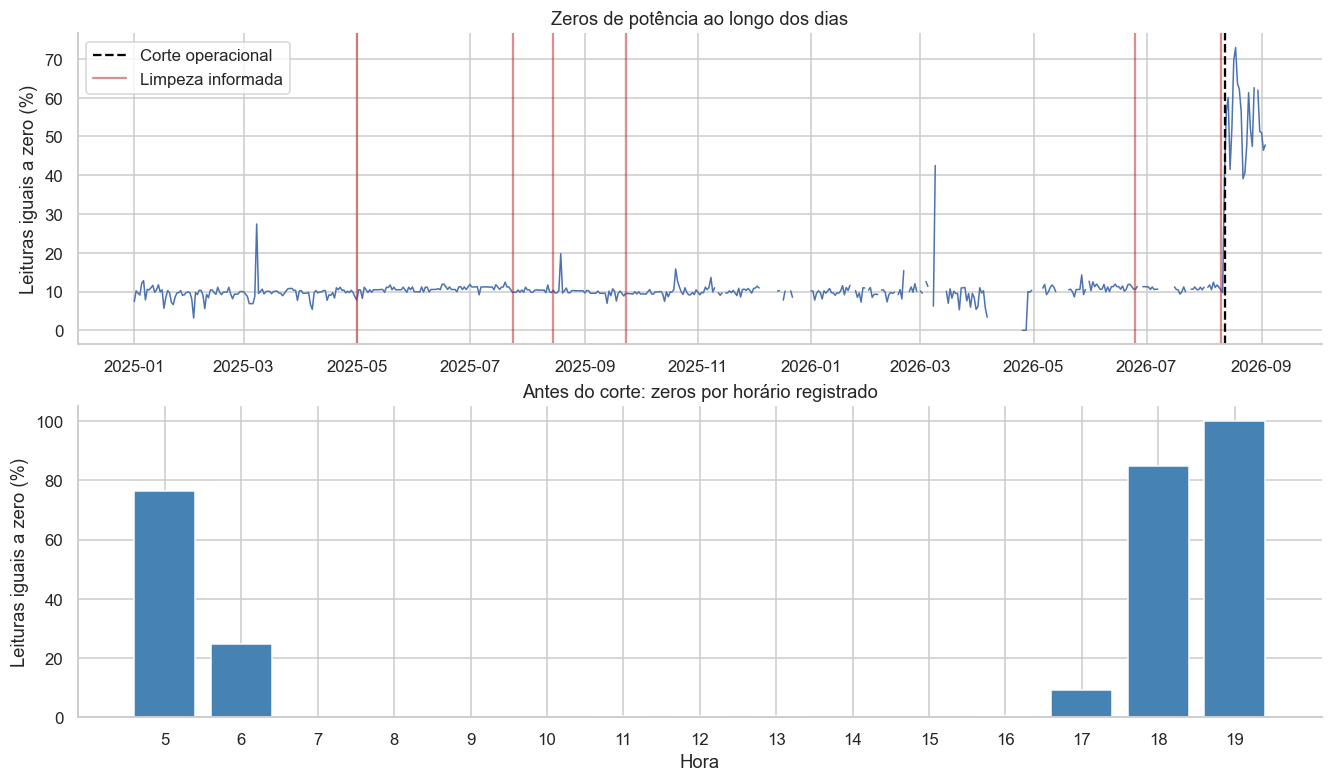

In [3]:
# O zero é uma leitura existente. Não é um horário sem registro.
daily_zeros = (
    paired.assign(day=paired["timestamp"].dt.normalize(), zero=paired["total_active_power"].eq(0))
    .groupby("day")
    .agg(pares=("timestamp", "size"), zeros=("zero", "sum"))
)
daily_zeros["zero_pct"] = daily_zeros["zeros"] / daily_zeros["pares"] * 100
daily_zeros = daily_zeros.reindex(pd.date_range(daily_zeros.index.min(), daily_zeros.index.max()))
before_cutoff = paired.loc[paired["timestamp"].lt(cutoff)].copy()
hourly_zeros = (
    before_cutoff.assign(
        hour=before_cutoff["timestamp"].dt.hour, zero=before_cutoff["total_active_power"].eq(0)
    )
    .groupby("hour")["zero"]
    .mean()
    .mul(100)
)

fig, axes = plt.subplots(2, 1, figsize=(12, 7), layout="constrained")
axes[0].plot(daily_zeros.index, daily_zeros["zero_pct"], linewidth=1)
axes[0].axvline(cutoff, color="black", linestyle="--", label="Corte operacional")
for i, event in enumerate(cleaning_dates[cleaning_dates <= paired["timestamp"].max()]):
    axes[0].axvline(
        event, color="firebrick", alpha=0.5, label="Limpeza informada" if i == 0 else None
    )
axes[0].set(title="Zeros de potência ao longo dos dias", ylabel="Leituras iguais a zero (%)")
axes[0].legend(loc="upper left")
axes[1].bar(hourly_zeros.index, hourly_zeros.values, color="steelblue")
axes[1].set(
    title="Antes do corte: zeros por horário registrado",
    xlabel="Hora",
    ylabel="Leituras iguais a zero (%)",
)
axes[1].set_xticks(hourly_zeros.index)
fig.savefig(FIGURES_DIR / "01_corte_operacional.png", bbox_inches="tight")
plt.show()

In [4]:
display(
    pd.DataFrame(
        [
            {
                "pares_antes_do_corte": len(paired),
                "pares_retirados": len(paired) - len(before_cutoff),
                "pares_restantes": len(before_cutoff),
                "ultimo_instante_restante": before_cutoff["timestamp"].max(),
            }
        ]
    )
)

,pares_antes_do_corte,pares_retirados,pares_restantes,ultimo_instante_restante
0,81859,3112,78747,2026-08-12 11:30:00


## 3. Formar blocos completos e calcular médias

Um bloco `[10:00, 10:30)` precisa ter os seis horários de `10:00` até `10:25`, de cinco
em cinco minutos, com potência, GHI e temperatura preenchidas. A data faz parte da chave.

**Decisão:** usar a **média**, não a soma. A potência continua em W. Não interpolamos
leituras ausentes; um bloco incompleto fica fora. Potência registrada como zero permanece.
Seis posições observadas não comprovam medição contínua de energia durante 30 minutos.

In [5]:
required = ["total_active_power", "ghi", "temp_amb"]
# Não aproximamos timestamps deslocados para obter artificialmente seis leituras.
if paired["timestamp"].ne(paired["timestamp"].dt.floor("5min")).any():
    raise ValueError("Há pares fora da grade de cinco minutos; investigar os relógios.")
if np.isinf(paired[required].to_numpy()).any():
    raise ValueError("Há valores infinitos nas medições; investigar a origem.")
if paired[["total_active_power", "ghi"]].lt(0).any().any():
    raise ValueError("Potência ou GHI negativas inesperadas; investigar antes de continuar.")

block_input = before_cutoff.assign(
    block_start=before_cutoff["timestamp"].dt.floor("30min"),
    valid_pair=before_cutoff[required].notna().all(axis=1),
    zero_power=before_cutoff["total_active_power"].eq(0),
)
blocks = (
    block_input.groupby("block_start")
    .agg(
        n_pairs=("timestamp", "size"),
        valid_pairs=("valid_pair", "sum"),
        power_count=("total_active_power", "count"),
        ghi_count=("ghi", "count"),
        temp_amb_count=("temp_amb", "count"),
        first_sample_timestamp=("timestamp", "min"),
        last_sample_timestamp=("timestamp", "max"),
        total_active_power=("total_active_power", "mean"),
        ghi=("ghi", "mean"),
        temp_amb=("temp_amb", "mean"),
        ghi_min=("ghi", "min"),
        ghi_max=("ghi", "max"),
        power_zero_count=("zero_power", "sum"),
    )
    .rename_axis("timestamp")
    .reset_index()
)
blocks["interval_end_exclusive"] = blocks["timestamp"] + pd.Timedelta(minutes=30)
blocks["coverage_fraction"] = blocks["n_pairs"] / 6
blocks["has_zero_power"] = blocks["power_zero_count"].gt(0)
complete = blocks["n_pairs"].eq(6) & blocks["valid_pairs"].eq(6)

display(
    pd.DataFrame(
        [
            {"situacao": "Bloco completo", "blocos": int(complete.sum())},
            {"situacao": "Menos de seis pares", "blocos": int(blocks["n_pairs"].lt(6).sum())},
            {
                "situacao": "Seis pares com medição ausente",
                "blocos": int((blocks["n_pairs"].eq(6) & ~complete).sum()),
            },
        ]
    )
)

,situacao,blocos
0,Bloco completo,12624
1,Menos de seis pares,935
2,Seis pares com medição ausente,0


## 4. Definir a população por irradiância

Não há GHI exatamente zero nos dados: o mínimo observado é aproximadamente **0,747 W/m²**.
Os valores baixos ficam concentrados na primeira barra do histograma, incluindo horários
registrados à noite. Por isso, `GHI ≥ 0` mantém todos os blocos completos.

A tabela e o gráfico mostram como o mínimo muda a cobertura. Não alteramos as leituras
baixas para zero; escolhemos quais condições ambientais entram nesta análise.

In [6]:
sensitivity = pd.DataFrame(
    [
        {
            "ghi_minima_W_m2": threshold,
            "blocos_com_todos_os_pontos_no_limiar": int(
                (complete & blocks["ghi_min"].ge(threshold)).sum()
            ),
        }
        for threshold in [0, 50, 100, 200]
    ]
)
display(sensitivity)

,ghi_minima_W_m2,blocos_com_todos_os_pontos_no_limiar
0,0,12624
1,50,10274
2,100,9543
3,200,7786


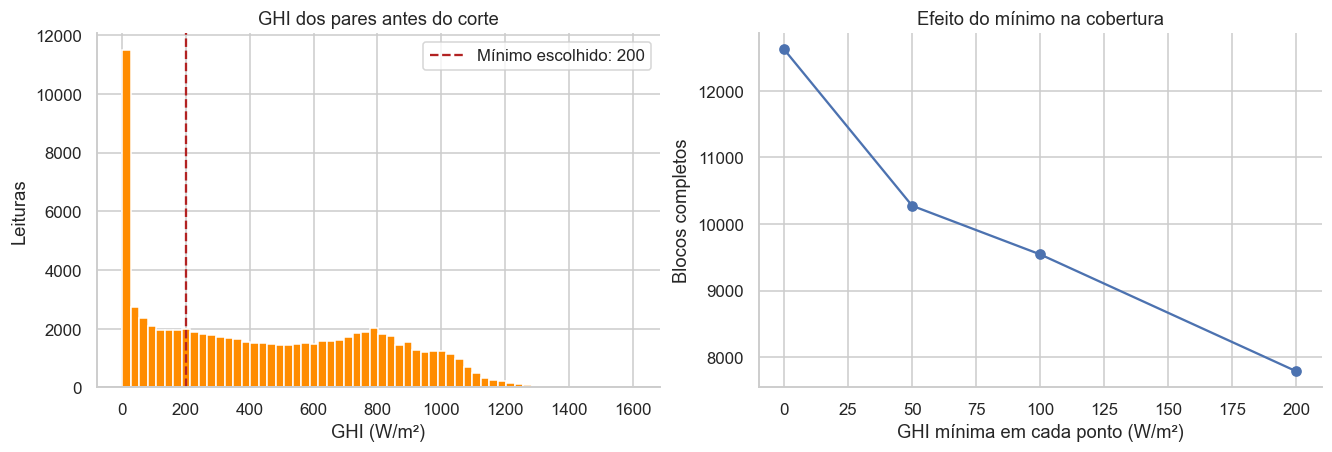

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
axes[0].hist(before_cutoff["ghi"], bins=60, color="darkorange")
axes[0].axvline(min_ghi, color="firebrick", linestyle="--", label="Mínimo escolhido: 200")
axes[0].set(title="GHI dos pares antes do corte", xlabel="GHI (W/m²)", ylabel="Leituras")
axes[0].legend()
axes[1].plot(
    sensitivity["ghi_minima_W_m2"], sensitivity["blocos_com_todos_os_pontos_no_limiar"], marker="o"
)
axes[1].set(
    title="Efeito do mínimo na cobertura",
    xlabel="GHI mínima em cada ponto (W/m²)",
    ylabel="Blocos completos",
)
fig.savefig(FIGURES_DIR / "03_sensibilidade_ghi.png", bbox_inches="tight")
plt.show()

**Decisão confirmada:** manter **GHI ≥ 200 W/m² em cada um dos seis pontos** como
configuração inicial. É um recorte conservador da população, não um limite ótimo comprovado.
Exigir apenas a média acima de 200 permitiria compensar leituras abaixo do limiar.

Não aplicamos teto de GHI nem de potência sem validação dos equipamentos. Zeros de potência
sob GHI alta continuam presentes e recebem indicadores; podem representar falhas ou perdas.

In [8]:
# Motivos exclusivos: primeiro cobertura, depois preenchimento e por último irradiância.
blocks["reason"] = np.select(
    [blocks["n_pairs"].ne(6), blocks["valid_pairs"].ne(6), blocks["ghi_min"].lt(min_ghi)],
    ["incomplete", "missing_required", "low_ghi"],
    default="eligible",
)
base_columns = [
    "timestamp",
    "total_active_power",
    "ghi",
    "temp_amb",
    "interval_end_exclusive",
    "last_sample_timestamp",
    "n_pairs",
    "coverage_fraction",
    "ghi_min",
    "ghi_max",
    "power_zero_count",
    "has_zero_power",
]
abt = blocks.loc[blocks["reason"].eq("eligible"), base_columns].reset_index(drop=True).copy()
funnel = pd.DataFrame(
    [
        ("exact_pairs", "pares de 5 min", len(paired), 0),
        ("before_cutoff", "pares de 5 min", len(before_cutoff), len(paired) - len(before_cutoff)),
        ("observed_blocks", "blocos de 30 min", len(blocks), 0),
        (
            "six_pairs_blocks",
            "blocos de 30 min",
            int(blocks["n_pairs"].eq(6).sum()),
            int(blocks["n_pairs"].ne(6).sum()),
        ),
        (
            "required_complete_blocks",
            "blocos de 30 min",
            int(complete.sum()),
            int((blocks["n_pairs"].eq(6) & ~complete).sum()),
        ),
        (
            "eligible_blocks",
            "blocos de 30 min",
            len(abt),
            int((complete & blocks["reason"].eq("low_ghi")).sum()),
        ),
    ],
    columns=["stage", "unit", "n", "removed_at_stage"],
)
display(
    funnel.rename(
        columns={
            "stage": "etapa",
            "unit": "unidade",
            "n": "quantidade",
            "removed_at_stage": "retirados",
        }
    )
)

,etapa,unidade,quantidade,retirados
0,exact_pairs,pares de 5 min,81859,0
1,before_cutoff,pares de 5 min,78747,3112
2,observed_blocks,blocos de 30 min,13559,0
3,six_pairs_blocks,blocos de 30 min,12624,935
4,required_complete_blocks,blocos de 30 min,12624,0
5,eligible_blocks,blocos de 30 min,7786,4838


In [9]:
display(
    pd.DataFrame(
        [
            {
                "blocos_entregues": len(abt),
                "com_alguma_potencia_zero": int(abt["has_zero_power"].sum()),
                "seis_potencias_zero": int(abt["power_zero_count"].eq(6).sum()),
                "celulas_nulas": int(abt.isna().sum().sum()),
            }
        ]
    )
)

,blocos_entregues,com_alguma_potencia_zero,seis_potencias_zero,celulas_nulas
0,7786,59,8,0


## 5. Marcar as janelas após limpeza

Sim: são **três colunas booleanas**, para 7, 15 e 30 dias. Por exemplo, no décimo dia após
uma limpeza, a flag de 7 dias é falsa e as de 15 e 30 são verdadeiras.

Começamos no dia seguinte à limpeza porque não sabemos seu horário de término. Uma nova
limpeza interrompe a janela anterior; dias sem dados não estendem sua duração.
Essas colunas são controles, não preditores. Estar fora de uma janela não significa “sujo”.

In [10]:
event_lookup = pd.DataFrame({"cleaning_date": cleaning_dates})
event_lookup["cleaning_event_id"] = event_lookup["cleaning_date"].dt.strftime("%Y-%m-%d")
# A limpeza mais recente evita que uma janela atravesse o próximo evento.
abt = pd.merge_asof(
    abt, event_lookup, left_on="timestamp", right_on="cleaning_date", direction="backward"
)
abt["days_since_cleaning"] = (
    (abt["timestamp"].dt.normalize() - abt["cleaning_date"]).dt.days.fillna(-1).astype(int)
)
abt["cleaning_event_id"] = abt["cleaning_event_id"].fillna("sem_evento_anterior")
abt = abt.drop(columns="cleaning_date")
abt["is_cleaning_day"] = abt["days_since_cleaning"].eq(0)
for k in window_days:
    abt[f"is_candidate_clean_{k}d"] = abt["days_since_cleaning"].between(1, k)

records = []
for i, event in enumerate(cleaning_dates):
    start = event + pd.Timedelta(days=1)
    record = {
        "event_id": event.strftime("%Y-%m-%d"),
        "cleaning_date": event,
        "window_start": start,
    }
    for k in window_days:
        end = start + pd.Timedelta(days=k)
        if i + 1 < len(cleaning_dates):
            end = min(end, cleaning_dates[i + 1])
        mask = abt["cleaning_event_id"].eq(record["event_id"]) & abt[f"is_candidate_clean_{k}d"]
        record[f"window_end_{k}d_exclusive"] = end
        record[f"blocks_{k}d"] = int(mask.sum())
        record[f"days_{k}d"] = int(abt.loc[mask, "timestamp"].dt.normalize().nunique())
    records.append(record)
events = pd.DataFrame(records)
display(events[["cleaning_date", "blocks_7d", "blocks_15d", "blocks_30d", "days_30d"]])

,cleaning_date,blocks_7d,blocks_15d,blocks_30d,days_30d
0,2025-05-01,100,218,443,30
1,2025-07-24,117,239,329,21
2,2025-08-15,101,238,500,30
3,2025-09-23,116,257,488,30
4,2026-06-25,66,141,272,18
5,2026-08-10,20,20,20,2
6,2026-10-03,0,0,0,0


A limpeza de 24/07 tem a janela de 30 dias interrompida em 15/08. Após 10/08/2026,
a análise só alcança 11 e 12/08 por causa do corte operacional. Outubro está fora dos dados.
Antes da primeira limpeza informada, `sem_evento_anterior` e `dias = -1` são códigos de controle.
Não preenchemos medições com esses valores.

## 6. Conferir e salvar a tabela

A amostra abaixo destaca alvo, preditores e alguns controles. A tabela exportada mantém
18 colunas, mas somente **`ghi` e `temp_amb`** são preditores ambientais nesta versão.
Vento, umidade e grandezas elétricas permanecem disponíveis nas tabelas do notebook 01.

In [11]:
display(
    abt[
        [
            "timestamp",
            "ghi",
            "temp_amb",
            "total_active_power",
            "n_pairs",
            "has_zero_power",
            "cleaning_event_id",
            "is_candidate_clean_30d",
        ]
    ].head(6)
)

,timestamp,ghi,temp_amb,total_active_power,n_pairs,has_zero_power,cleaning_event_id,is_candidate_clean_30d
0,2025-01-01 07:30:00,406.071100,27.668662,6766.000000,6,False,sem_evento_anterior,False
1,2025-01-01 08:00:00,496.133315,27.899328,8569.666667,6,False,sem_evento_anterior,False
2,2025-01-01 08:30:00,691.164443,28.365997,12022.000000,6,False,sem_evento_anterior,False
3,2025-01-01 09:00:00,779.253332,29.677327,13569.500000,6,False,sem_evento_anterior,False
4,2025-01-01 09:30:00,861.199997,30.784667,15072.000000,6,False,sem_evento_anterior,False
5,2025-01-01 10:00:00,939.368870,32.342658,16371.000000,6,False,sem_evento_anterior,False


In [12]:
# Sobrescreve os mesmos arquivos da entrega; não cria versões concorrentes.
datasets = {}
for name, stem, frame in [
    ("abt", "abt_30min", abt),
    ("events", "cleaning_events", events),
    ("block_audit", "block_audit", blocks),
]:
    frame.to_parquet(GOLD_DIR / f"{stem}.parquet", index=False)
    if name != "block_audit":
        frame.to_csv(GOLD_DIR / f"{stem}.csv", index=False)
    datasets[name] = {
        "file": f"{stem}.parquet",
        "rows": len(frame),
        "columns": frame.columns.tolist(),
        "dtypes": frame.dtypes.astype(str).to_dict(),
    }
funnel.to_csv(GOLD_DIR / "funnel.csv", index=False)
source_audit.to_csv(GOLD_DIR / "source_audit.csv", index=False)

column_dictionary = {
    "timestamp": "Início do bloco datado, sem conversão de fuso.",
    "total_active_power": "Alvo: potência ativa AC média dos seis pontos, em W.",
    "ghi": "Preditor: GHI média dos mesmos seis pontos, em W/m².",
    "temp_amb": "Preditor: temperatura ambiente média dos mesmos seis pontos, em °C.",
    "interval_end_exclusive": "Fim exclusivo do agrupamento, início + 30 minutos.",
    "last_sample_timestamp": "Último ponto observado, início + 25 minutos.",
    "n_pairs": "Seis timestamps pareados, únicos e preenchidos.",
    "coverage_fraction": "n_pairs / 6; igual a 1 nos blocos entregues.",
    "ghi_min": "Menor GHI do bloco, usada para o recorte.",
    "ghi_max": "Maior GHI do bloco; sem teto artificial.",
    "power_zero_count": "Quantidade de potências iguais a zero no bloco.",
    "has_zero_power": "Se há alguma potência registrada como zero.",
    "cleaning_event_id": "Data da última limpeza informada, ou sem_evento_anterior.",
    "days_since_cleaning": "Dias de calendário desde a limpeza; -1 antes do primeiro evento.",
    "is_cleaning_day": "Se o bloco pertence ao próprio dia da limpeza.",
}
for k in window_days:
    column_dictionary[f"is_candidate_clean_{k}d"] = f"Dias 1 a {k} após a limpeza mais recente."
metadata = {
    "layer": "gold",
    "generated_at_utc": datetime.now(UTC).isoformat(),
    "config": {"min_ghi": min_ghi, "cutoff": str(cutoff), "window_days": list(window_days)},
    "source_minutes": 5,
    "block_minutes": 30,
    "datasets": datasets,
    "feature_columns": ["ghi", "temp_amb"],
    "target_column": "total_active_power",
    "control_columns": [c for c in abt.columns if c not in required],
    "column_dictionary": column_dictionary,
    "source_audit": source_audit.to_dict("records"),
    "silver_sha256": {
        p.name: hashlib.sha256(p.read_bytes()).hexdigest()
        for p in SILVER_DIR.iterdir()
        if p.name in ["inverter.parquet", "weather.parquet", "metadata.json"]
    },
    "rules": [
        "Pareamento exato antes das médias",
        "Corte operacional estrito",
        "Seis pontos únicos e preenchidos por bloco",
        "GHI >= 200 em cada ponto",
        "Zeros de potência preservados",
        "Sem interpolação ou conversão de fuso",
        "Janelas candidatas começam no dia seguinte e terminam antes da próxima limpeza",
    ],
    "contract": {
        "main_table_null_cells": int(abt.isna().sum().sum()),
        "required_pairs_per_block": 6,
        "all_six_ghi_at_least": min_ghi,
        "zeros_preserved": True,
    },
}
(GOLD_DIR / "metadata.json").write_text(
    json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8"
)

6713

In [13]:
saved = pd.read_parquet(GOLD_DIR / "abt_30min.parquet")
display(
    pd.DataFrame(
        [
            {
                "linhas": len(saved),
                "colunas": saved.shape[1],
                "nulos": int(saved.isna().sum().sum()),
                "timestamps_duplicados": int(saved["timestamp"].duplicated().sum()),
                "todos_os_blocos_com_seis_pares": bool(saved["n_pairs"].eq(6).all()),
                "arquivo_igual_a_tabela": saved.equals(abt),
                "candidatos_30d": int(saved["is_candidate_clean_30d"].sum()),
            }
        ]
    )
)

,linhas,colunas,nulos,timestamps_duplicados,todos_os_blocos_com_seis_pares,arquivo_igual_a_tabela,candidatos_30d
0,7786,18,0,0,True,True,2052


Entrega: **`data/gold/abt_30min.parquet`**, também em CSV. Os arquivos auxiliares registram
cobertura das limpezas, motivos de exclusão e dicionário de colunas.

A equipe de ML deve definir treino e avaliação por datas/eventos. A janela pós-limpeza é
candidata; déficits futuros também podem incluir falhas e erro de referência. Esta tabela
não representa toda a energia diária e não contém cálculos de kWh.